# 3. Draw maps

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/03_maps.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/03_maps.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/banner-3.svg" alt="duckOSM notebook manual, chapter 3: Draw maps" width="100%">

| **You learn** | the live map and the static picture; how a notebook shows a map (`show=`); the map of one mode; the base map (`layers=`); the themes; the colors of the modes; color by a column; highlight edges; the dashboard; a map as an HTML file; a picture for a paper |
|---|---|
| **Time** | about 2 minutes |
| **Extras** | `duckosm[viz]` (the install cell installs them) |
| **Next** | [4. Join your data by edge_id](04_join_by_edge_id.md): your own data on the edges, and on the map |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
import importlib.util, json, urllib.request
def nightly_wheel():       # the address of the newest nightly wheel
    release = json.load(urllib.request.urlopen("https://api.github.com/repos/Khoshkhah/duckOSM/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[viz] @ {nightly_wheel()}"
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


## Two kinds of map

duckOSM draws a network in two ways.

| | The live map | The static picture |
|---|---|---|
| Made by | [roadstyle](https://github.com/Khoshkhah/roadstyle), in the browser (MapLibre) | matplotlib, in Python |
| Calls | `net.map()`, `net.dashboard()`, `net.save_map()` | `net.plot()`, or `show="plot"` |
| You can | zoom, pan, click a road to see its columns, turn the layers on and off | save it as PNG or PDF, put it in a paper, draw it on your own axes |
| Draws | the roads with their casing, bridges over tunnels, the base map of the file, the labels | the roads as lines, and five layers of the base map |
| Size in the notebook (Monaco) | about 6 MB | a small PNG |

The live map of Monaco looks like this. It shows the roads of all modes over the base map of the file: the
buildings, the harbors, the parks. The tunnels are dashed, and the bridges are drawn over the roads under them.

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/map-live-monaco.png" alt="The live roadstyle map of Monaco, with all modes and the base map" width="100%">

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> The same call gives a live map or a picture. `net.map()` gives the live map in a notebook. With `show="plot"`, it gives the static picture, with the same options. So you write the map once and choose later how to show it.

## How this page shows the maps

A live map is a web page of approximately 6 MB. A saved notebook with many live maps is large, and GitHub does not
show it. So the outputs on this page come from a run with `DUCKOSM_MAP_SHOW=plot`: each map is the static picture.
When you run the cells yourself, you get the live map.

The argument `show` chooses how the notebook shows a map. Without it, duckOSM uses the environment variable
`DUCKOSM_MAP_SHOW`, and without that, `"live"`.

| `show` | What you get when you run the cell | Size (Monaco) |
|---|---|---|
| `"live"` | the live roadstyle map in the output of the cell | about 6 MB in the notebook |
| `"link"` | the live map saved as an HTML file, and a link "Open the live map" in the output | a link; the file is about 6 MB |
| `"picture"` | a PNG of the live map, taken in a hidden Chromium browser | about 150 KB |
| `"plot"` | `net.plot()`: the matplotlib picture, without roadstyle | a small PNG |

`"link"` and `"picture"` write their file to `path`. The default is `maps/<file>-<n>.html` or
`maps/<file>-<n>.png`, where `<n>` counts the maps of the session. `"picture"` needs Playwright:
`pip install playwright`, then `playwright install chromium`.

```python
net.map(show="link", path="maps/monaco.html")      # a link to the saved live map
net.map(show="picture", path="maps/monaco.png")    # a PNG of the live map
import os
os.environ["DUCKOSM_MAP_SHOW"] = "picture"         # the default for all maps of this session
```

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> Use `"link"` in a notebook that you share: the notebook stays small, and the HTML file opens in each browser without a server. Use `"picture"` when you want the look of the live map in a saved notebook.

## Build the network of this chapter

The chapter uses the three modes of Monaco, so that the map can show which modes can use each road.

In [2]:
net = duckosm.network(osm_id=2220322, modes=["driving", "walking", "cycling"], name="monaco")    # three modes
net.summary()

cut: 34461 nodes, 5685 ways, 339 relations

Output: ~/.cache/duckosm/work/monaco-20261120-194937-e340/monaco.duckdb

,mode,edges,nodes,km,oneway_km
0,driving,2840,1768,96.2,35.5
1,walking,11938,4589,260.6,0.0
2,cycling,11305,4650,250.0,35.5


## The map of all modes: `net.map()`

`net.map()` with no mode draws all the roads of the file. In a live notebook, it is the roadstyle map: the roads of
all modes, the drawing order of the bridges and the tunnels, and the base map of the file. Click a road to see its
columns: its `edge_id`, its name, its road class and its modes.

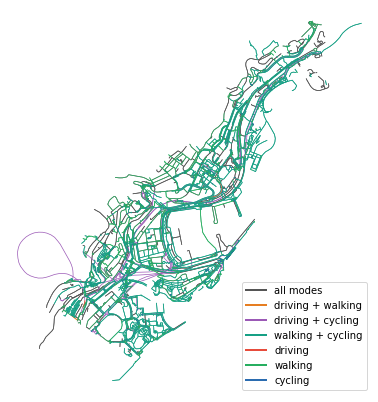

In [3]:
net.map()          # the live map of all modes (this page: the static picture)

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The picture has one color for each set of modes that can use a road. Most of the roads are green-blue (walking and cycling: the footways and the paths). The streets that all modes can use are dark gray. The tunnel loop in the west is purple: cars and bicycles can use it, but people on foot cannot. The legend lists the sets.

### The color of a road in more than one mode

A road can be in one, two or three modes (chapter 2, "The same edge in each mode"). The map draws each road once,
with the color of its set of modes. These are the colors of the "Modes" option of the dashboard, so the picture and
the dashboard agree.

| Modes that can use the road | Name in the legend | Color |
|---|---|---|
| driving, walking and cycling | all modes | dark gray `#555555` |
| driving and walking | driving + walking | orange `#e67e22` |
| driving and cycling | driving + cycling | purple `#9b59b6` |
| walking and cycling | walking + cycling | green-blue `#16a085` |
| driving only | driving | red `#e74c3c` |
| walking only | walking | green `#27ae60` |
| cycling only | cycling | blue `#2b6cb0` |

The cell below counts the roads of each set, with the same rule: the modes of each `edge_id`.

In [4]:
edges = net.edges()                                                   # all modes, with a "mode" column
order = ["driving", "walking", "cycling"]
sets = edges.groupby("edge_id")["mode"].agg(lambda m: " + ".join(x for x in order if x in set(m)))
sets.value_counts()                                                   # the roads of each set of modes

mode
walking + cycling              7751
driving + walking + cycling    2196
walking                        1986
cycling                         725
driving + cycling               633
driving                           6
driving + walking                 5
Name: count, dtype: int64

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> Of the 13302 roads, 7751 are for walking and cycling only, and 2196 are for all modes. Only 6 roads are for driving only (most motor roads of Monaco have a sidewalk or allow bicycles), and 5 are for driving and walking. The legend shows "all modes" in place of "driving + walking + cycling".

## The map of one mode

`net.map("driving")`, or `net.driving.map()`, draws one mode. The live map uses the style of that mode. The static
picture gives one color to each road class (`highway`).

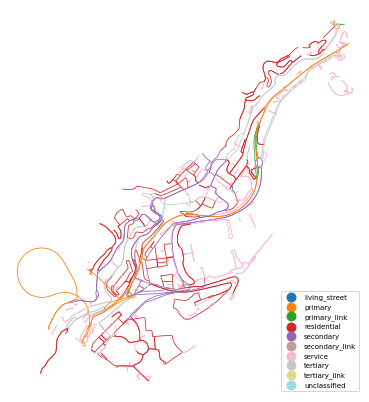

In [5]:
net.map("driving")          # the driving network, by road class

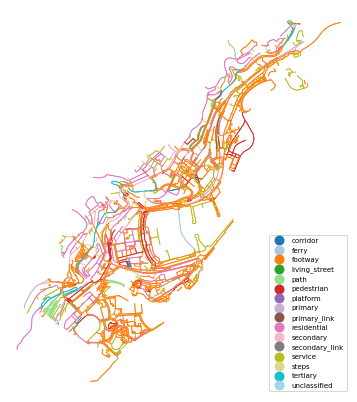

In [6]:
net.walking.map()           # the same call on the view of one mode

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The driving picture shows the main roads along the coast and the tunnel loop in the west. The walking picture is much denser: it has the steps and the footways of the old town.

## The base map: `layers`

`layers` chooses the base map under the roads.

| `layers` | The live map | The static picture |
|---|---|---|
| not given | all layers of the file | the roads only |
| `True` | all layers | the five layers below |
| `False` | the roads only | the roads only |
| a list of names | those layers | those layers, of the five |

The static picture draws five layers: `ocean`, `landcover`, `water`, `waterways` and `buildings`. The live map has
all the layers of roadstyle, for example `paved`, `railways`, `parking`, `traffic_signals`, `crossings` and
`train_stations`. Its layers button turns each one on and off.

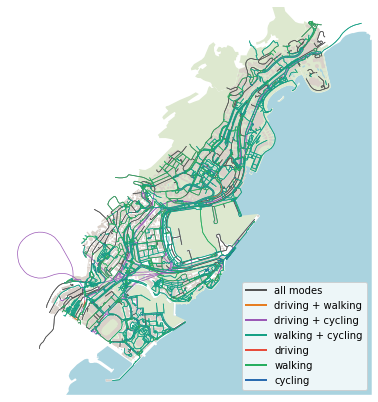

In [7]:
net.map(layers=True)                                 # the roads over the base map

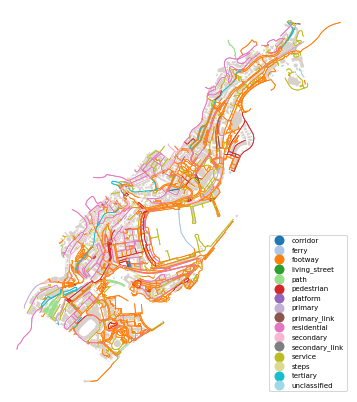

In [8]:
net.plot("walking", layers=["water", "buildings"])    # two layers of the base map

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The first picture has the sea, the land cover and the buildings under the roads. The view stops at a small margin around the roads, so the sea does not fill the picture. The second picture has only the buildings (light gray) and the small water areas. Another name gives an error that lists the five layers of the picture.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> With `color_by` or `routes`, the live map has the default base map of roadstyle, and `layers` has no effect. This limit of roadstyle can change in a later version.

## The themes: `theme`

`theme` chooses the colors of the live map: `"liberty"` (the default), `"osm"`, `"google"`, `"grey"` or
`"roadstyle"`. The static picture has one look, so `theme` changes only the live map. The cell saves the map with the
theme `"grey"` as an HTML file (section "Save a map as a file" below). Open the file in a browser to see it.

In [9]:
net.save_map("out/monaco-grey.html", theme="grey")      # the live map with the gray theme, as a file

PosixPath('out/monaco-grey.html')

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The call gives the path of the file. The file is one HTML page of approximately 6 MB, and it works without a server and without the internet.

## Color the roads by a column: `color_by`

`color_by` gives each road a color from a column. A number column gets a color ramp: `cmap` chooses it (a matplotlib
name, for example `"viridis"` or `"magma_r"`). A text column has classes: give `colors`, a dict of value and color.
Roads without a value are gray.

| Option | Takes |
|---|---|
| `color_by` | the name of a column of the edges, or your own data: a pandas Series with `edge_id` as its index, or a DataFrame with `edge_id` and one value column (chapter 4) |
| `cmap` | the color ramp of a number column |
| `colors` | `{value: color}` for a text column |

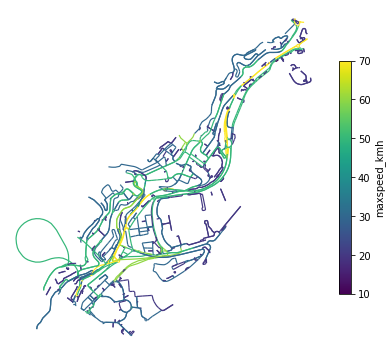

In [10]:
net.map("driving", color_by="maxspeed_kmh", cmap="viridis")      # the speed limit of each road

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The color bar goes from 10 to 70 km/h. The fast roads (yellow) are the main roads and the tunnels along the coast. Most streets of the town have 30 km/h or less (dark blue).

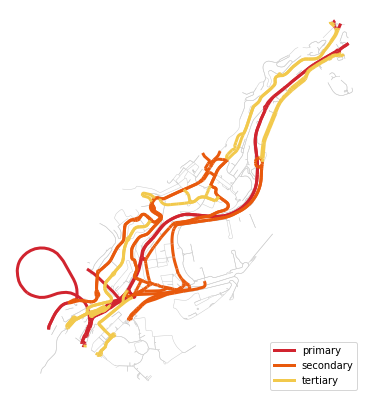

In [11]:
net.map("driving", color_by="highway",
        colors={"primary": "#d1242f", "secondary": "#e8590c", "tertiary": "#f2c94c"})   # three classes, the rest gray

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The primary roads are red, the secondary roads orange and the tertiary roads yellow. The other classes are thin gray lines.

## Highlight some edges: `highlight`

`highlight` takes a list of `edge_id` values. These edges are orange, and all other edges are gray. Use it to show
the result of a query.

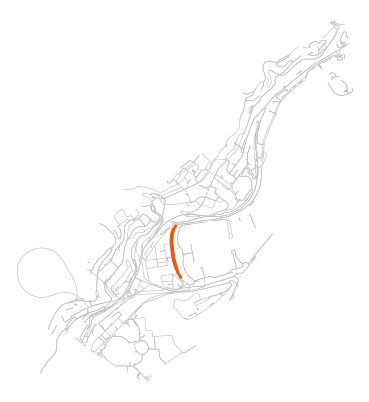

In [12]:
albert = net.sql("SELECT edge_id FROM driving.edges WHERE name = 'Boulevard Albert 1er'").edge_id   # one street
net.map("driving", highlight=albert)                                                              # in orange

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The Boulevard Albert 1er is the orange line along the harbor of Monaco.

## Draw a route: `routes`

`routes` draws one route, a list of routes or a dict of label and route over the roads, each in its own color.
Chapter 7 tells how to compute a route. Here the route goes by car from the south-west of Monaco to the north-east.

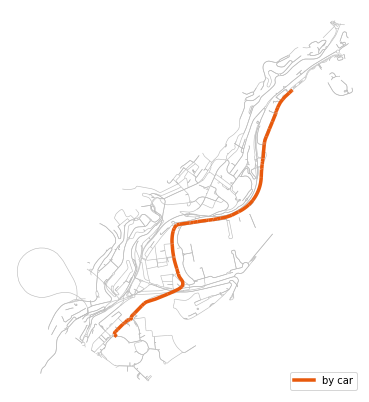

In [13]:
route = net.driving.route_points((7.4155, 43.7285), (7.4335, 43.7468))     # (lon, lat) to (lon, lat)
net.map("driving", routes={"by car": route})                                # the route over the roads

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The route is the orange line with the label "by car" in the legend. In the live map, click the line to see its time and its length.

## The dashboard: `net.dashboard()`

`net.dashboard()` is roadstyle's dashboard page: the live map with a panel docked beside it. Click a road, and the
panel shows its card: all its columns. The color menu of the panel colors the roads by road class or by **Modes**
(the colors of the table in "The color of a road in more than one mode"). `mode`, `show`, `path` and `layers` work as
in `net.map()`.

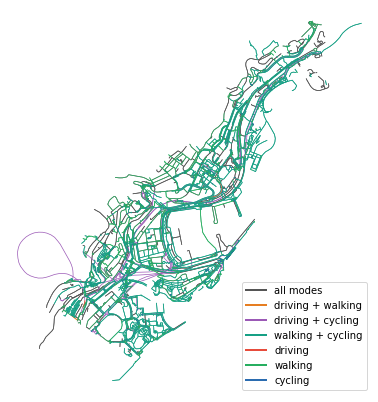

In [14]:
net.dashboard()            # the dashboard of all modes (this page: the static picture)

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> With `show="plot"`, the dashboard is the same picture as `net.map()`: a static picture has no panel. Run the cell in a live notebook to see the panel.

## Save a map as a file: `net.save_map()`

`net.save_map(path)` writes the live map as one offline HTML file and gives its path. It takes the options of
`net.map()`: `mode`, `theme`, `color_by`, `highlight`, `routes` and `layers`. With `dashboard=True`, it writes the
dashboard. Send the file to a person who has no Python: it opens in each browser.

In [15]:
print(net.save_map("out/monaco.html"))                                          # the map of all modes
print(net.save_map("out/driving-speed.html", "driving", color_by="maxspeed_kmh"))  # one mode, colored
print(net.save_map("out/dashboard.html", dashboard=True))                        # the dashboard

out/monaco.html


out/driving-speed.html


out/dashboard.html


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> Three HTML files in the folder `out`. The map of one mode is smaller than the map of all modes, because it has fewer roads.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> `net.save_map()` gives the same file as `net.map(show="link", path=...)`, but it shows no link. Use it in a script.

## A picture for a paper: `net.plot()`

`net.plot()` is the static picture. It takes the options of `net.map()` (`color_by`, `cmap`, `colors`, `highlight`,
`routes`) and `layers` (default `False`: the roads only). With `ax`, it draws on your own matplotlib axes and gives
them back, so you can put more maps in one figure and save it.

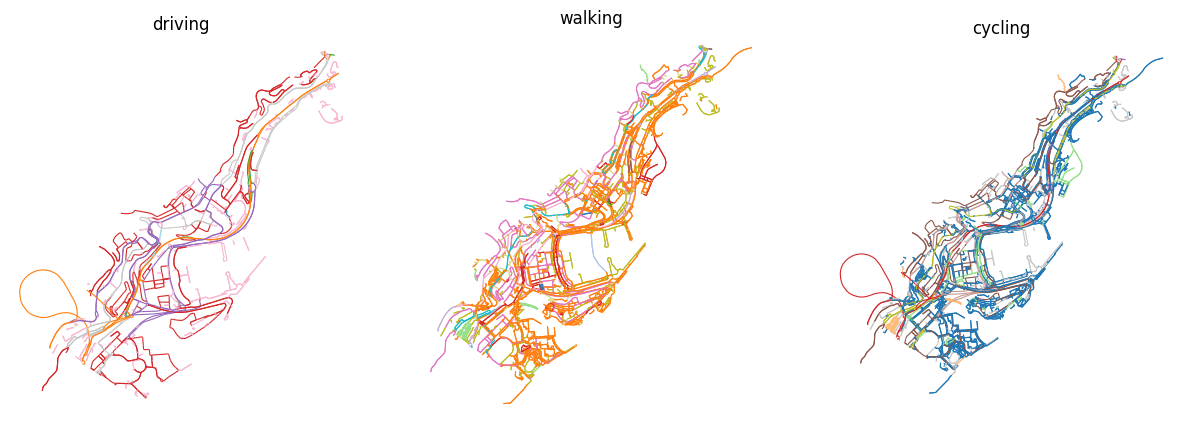

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))           # three maps side by side
for ax, mode in zip(axes, net.modes):
    net.plot(mode, ax=ax)                                 # each mode on its own axes
    ax.set_title(mode)
    ax.get_legend().remove()                              # no legend of road classes: the figure stays small
fig.savefig("out/modes.png", dpi=150, bbox_inches="tight")  # a PNG for a paper (".pdf" gives a PDF)
plt.show()

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The three networks side by side, each with the colors of its road classes. Walking has no tunnel loop in the west, and it is the densest network. The file `out/modes.png` has the same figure at 150 dots per inch.

## Try it yourself

**1.** Draw the walking network, colored by `length_m`, with the color ramp `"plasma"`.

<details><summary>Show the answer</summary>

```python
net.map("walking", color_by="length_m", cmap="plasma")
```
</details>

**2.** Highlight the steps of the walking network.

<details><summary>Show the answer</summary>

```python
steps = net.walking.edges(where="highway = 'steps'").edge_id
net.map("walking", highlight=steps)
```
</details>

**3.** Save the dashboard of the cycling network as `out/cycling.html`, with the theme `"osm"`.

<details><summary>Show the answer</summary>

```python
net.save_map("out/cycling.html", "cycling", dashboard=True, theme="osm")
```
</details>

**4.** Make a picture of the driving network over the buildings and the water, and save it as a PDF.

<details><summary>Show the answer</summary>

```python
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 8))
net.plot("driving", layers=["water", "buildings"], ax=ax)
fig.savefig("out/driving.pdf")
```
</details>

## Words in this chapter

| Word | Meaning |
|---|---|
| live map | the roadstyle map in the browser: you can zoom and click |
| static picture | the matplotlib picture of `net.plot()`: a PNG or a PDF |
| roadstyle | the library that draws the live map and the dashboard |
| base map | the layers under the roads: buildings, water, land, from the `features` schema |
| theme | the colors of the live map: liberty, osm, google, grey, roadstyle |
| color ramp | a range of colors for a number column (`cmap`) |
| dashboard | the live map with a panel: the card of the road that you click, and the color menu |
| `DUCKOSM_MAP_SHOW` | the environment variable that gives the default of `show` |

## Summary

| Call | Does |
|---|---|
| `net.map(mode=None, show=, path=, layers=, theme=)` | the live map; `show` chooses live, link, picture or plot |
| `net.map(..., color_by=, cmap=, colors=)` | the roads colored by a column or by your own data |
| `net.map(..., highlight=)` | some edges in orange, the rest gray |
| `net.map(..., routes=)` | routes over the roads |
| `net.dashboard(mode=None, show=, path=, layers=)` | the live map with the panel: the road card and the color menu |
| `net.save_map(path, mode=None, dashboard=False, **options)` | the live map or the dashboard as one HTML file |
| `net.plot(mode=None, layers=False, ax=None, ...)` | the static matplotlib picture |
| `net.walking.map()`, `.plot()`, `.dashboard()`, `.save_map()` | the same calls for one mode |

The reference: [Python SDK, Maps](../reference/python.md#maps). **Next:** [4. Join your data by edge_id](04_join_by_edge_id.md), your own data on the edges, and on the map.